<a href="https://colab.research.google.com/github/sofiasaputri810/karhutla-risk-prediction-kalimantan/blob/main/karhutla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# AKUISISI DATA KARHUTLA KALIMANTAN
# NASA FIRMS (titik panas) + NASA POWER (cuaca)
# ============================================================

!pip install -q requests pandas numpy

import requests
import pandas as pd
import numpy as np
import io
from datetime import datetime, timedelta

# ============================================================
# KONFIGURASI
# ============================================================
MAP_KEY = "c886f7139d0162a95e850ddc928ed680"

# Bounding box Kalimantan: west,south,east,north
# Format API FIRMS: [west, south, east, north]
BBOX_KALIMANTAN = "108,-4,120,4"

# Periode data
START_DATE = "2026-03-25"
END_DATE = "2026-10-25"

# Sensor: VIIRS NOAA-20 Near Real-Time (resolusi ~375m)
SENSOR = "VIIRS_NOAA20_NRT"

# ============================================================
# FUNGSI 1: AMBIL TITIK PANAS DARI NASA FIRMS
# ============================================================
def fetch_firms_hotspots(map_key, sensor, bbox, start_date, end_date):
    """
    Mengambil data titik panas dari FIRMS API.
    API membatasi maksimal 5 hari per request, jadi kita loop per 5 hari.
    """
    all_data = []
    current = datetime.strptime(start_date, "%Y-%m-%d")
    end = datetime.strptime(end_date, "%Y-%m-%d")

    while current <= end:
        # Hitung tanggal akhir chunk (maks 5 hari)
        chunk_end = min(current + timedelta(days=4), end)

        # Format URL: /api/area/csv/[MAP_KEY]/[SOURCE]/[BBOX]/[DAY_RANGE]/[DATE]
        day_range = (chunk_end - current).days + 1
        date_str = current.strftime("%Y-%m-%d")

        url = (
            f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/"
            f"{map_key}/{sensor}/{bbox}/{day_range}/{date_str}"
        )

        print(f"Mengambil FIRMS: {date_str} s/d {chunk_end.strftime('%Y-%m-%d')}...")

        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()

            if response.text.strip():
                df_chunk = pd.read_csv(io.StringIO(response.text))
                all_data.append(df_chunk)
                print(f"  -> {len(df_chunk)} titik panas")
            else:
                print(f"  -> tidak ada data")

        except Exception as e:
            print(f"  -> GAGAL: {e}")

        current = chunk_end + timedelta(days=1)

    if all_data:
        return pd.concat(all_data, ignore_index=True)
    else:
        return pd.DataFrame()


# ============================================================
# FUNGSI 2: AMBIL CUACA DARI NASA POWER
# ============================================================
def fetch_power_weather(lat, lon, start_date, end_date):
    """
    Mengambil data cuaca harian dari NASA POWER untuk satu titik koordinat.
    Parameter: T2M_MAX (suhu maks), RH2M (kelembaban), WS2M (angin), PRECTOTCORR (hujan).
    """
    start_fmt = start_date.replace("-", "")
    end_fmt = end_date.replace("-", "")

    url = "https://power.larc.nasa.gov/api/temporal/daily/point"
    params = {
        "parameters": "T2M_MAX,RH2M,WS2M,PRECTOTCORR",
        "community": "RE",
        "latitude": lat,
        "longitude": lon,
        "start": start_fmt,
        "end": end_fmt,
        "format": "JSON"
    }

    try:
        response = requests.get(url, params=params, timeout=60)
        response.raise_for_status()
        data = response.json()

        # Ekstrak parameter dari respons JSON
        params_data = data["properties"]["parameter"]
        df = pd.DataFrame({
            "date": list(params_data["T2M_MAX"].keys()),
            "t2m_max": list(params_data["T2M_MAX"].values()),
            "rh2m": list(params_data["RH2M"].values()),
            "ws2m": list(params_data["WS2M"].values()),
            "prectotcorr": list(params_data["PRECTOTCORR"].values()),
        })
        df["date"] = pd.to_datetime(df["date"], format="%Y%m%d")
        df["lat_grid"] = lat
        df["lon_grid"] = lon
        return df

    except Exception as e:
        print(f"  -> POWER GAGAL untuk ({lat},{lon}): {e}")
        return pd.DataFrame()


# ============================================================
# EKSEKUSI: AMBIL TITIK PANAS
# ============================================================
print("=" * 50)
print("TAHAP 1: MENGAMBIL DATA TITIK PANAS (FIRMS)")
print("=" * 50)

df_firms = fetch_firms_hotspots(
    MAP_KEY, SENSOR, BBOX_KALIMANTAN, START_DATE, END_DATE
)

if df_firms.empty:
    print("\n⚠️ Tidak ada data FIRMS. Periksa MAP_KEY dan rentang tanggal.")
else:
    print(f"\nTotal titik panas: {len(df_firms)}")
    print(f"Kolom: {list(df_firms.columns)}")
    print(df_firms.head())

# ============================================================
# EKSEKUSI: AMBIL CUACA UNTUK GRID YANG ADA TITIK PANASNYA
# ============================================================
print("\n" + "=" * 50)
print("TAHAP 2: MENGAMBIL DATA CUACA (NASA POWER)")
print("=" * 50)

if not df_firms.empty:
    # Buat grid kasar (0.5°) dari koordinat titik panas
    # NASA POWER resolusi meteorologi ~0.5°, jadi kita round ke 0.5 terdekat
    df_firms["lat_grid"] = (df_firms["latitude"] / 0.5).round() * 0.5
    df_firms["lon_grid"] = (df_firms["longitude"] / 0.5).round() * 0.5

    # Ambil kombinasi grid unik
    unique_grids = df_firms[["lat_grid", "lon_grid"]].drop_duplicates()
    print(f"Jumlah grid unik: {len(unique_grids)}")

    # Loop ambil cuaca per grid
    weather_list = []
    for i, row in unique_grids.iterrows():
        print(f"  Grid {i+1}/{len(unique_grids)}: ({row['lat_grid']}, {row['lon_grid']})")
        df_w = fetch_power_weather(
            row["lat_grid"], row["lon_grid"], START_DATE, END_DATE
        )
        if not df_w.empty:
            weather_list.append(df_w)

    if weather_list:
        df_power = pd.concat(weather_list, ignore_index=True)
        print(f"\nTotal baris cuaca: {len(df_power)}")
        print(df_power.head())
    else:
        df_power = pd.DataFrame()
        print("\n⚠️ Tidak ada data cuaca yang berhasil diambil.")
else:
    df_power = pd.DataFrame()
    print("Lewati POWER karena tidak ada titik panas.")

# ============================================================
# TAHAP 3: GABUNGKAN (PREVIEW)
# ============================================================
print("\n" + "=" * 50)
print("TAHAP 3: PENGGABUNGAN DATA")
print("=" * 50)

if not df_firms.empty and not df_power.empty:
    # Konversi kolom tanggal FIRMS (kolom 'acq_date') ke datetime
    df_firms["acq_date"] = pd.to_datetime(df_firms["acq_date"])

    # Agregasi titik panas per grid per hari
    df_hotspot_agg = (
        df_firms.groupby(["lat_grid", "lon_grid", "acq_date"])
        .size()
        .reset_index(name="hotspot_count")
    )

    # Gabungkan dengan cuaca (merge pada grid + tanggal)
    df_merged = df_hotspot_agg.merge(
        df_power,
        left_on=["lat_grid", "lon_grid", "acq_date"],
        right_on=["lat_grid", "lon_grid", "date"],
        how="left"
    )

    print(f"Baris hasil merge: {len(df_merged)}")
    print(df_merged.head(10))

    # Simpan ke CSV
    df_merged.to_csv("karhutla_kalimantan_merged.csv", index=False)
    print("\n✅ Data tersimpan: karhutla_kalimantan_merged.csv")
else:
    print("⚠️ Merge tidak bisa dilakukan karena salah satu dataset kosong.")

print("\nSELESAI. Jalankan sel berikutnya untuk EDA dan modeling.")

TAHAP 1: MENGAMBIL DATA TITIK PANAS (FIRMS)
Mengambil FIRMS: 2026-03-25 s/d 2026-03-29...
  -> 0 titik panas
Mengambil FIRMS: 2026-03-30 s/d 2026-04-03...
  -> 0 titik panas
Mengambil FIRMS: 2026-04-04 s/d 2026-04-08...
  -> 0 titik panas
Mengambil FIRMS: 2026-04-09 s/d 2026-04-13...
  -> 0 titik panas
Mengambil FIRMS: 2026-04-14 s/d 2026-04-18...
  -> 0 titik panas
Mengambil FIRMS: 2026-04-19 s/d 2026-04-23...
  -> 0 titik panas
Mengambil FIRMS: 2026-04-24 s/d 2026-04-28...
  -> 0 titik panas
Mengambil FIRMS: 2026-04-29 s/d 2026-05-03...
  -> 0 titik panas
Mengambil FIRMS: 2026-05-04 s/d 2026-05-08...
  -> 0 titik panas
Mengambil FIRMS: 2026-05-09 s/d 2026-05-13...
  -> 0 titik panas
Mengambil FIRMS: 2026-05-14 s/d 2026-05-18...
  -> 0 titik panas
Mengambil FIRMS: 2026-05-19 s/d 2026-05-23...
  -> 0 titik panas
Mengambil FIRMS: 2026-05-24 s/d 2026-05-28...
  -> 0 titik panas
Mengambil FIRMS: 2026-05-29 s/d 2026-06-02...
  -> 0 titik panas
Mengambil FIRMS: 2026-06-03 s/d 2026-06-07...


/tmp/ipykernel_620/2262825328.py:74: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(all_data, ignore_index=True)


  Grid 3/285: (-3.0, 115.5)
  Grid 4/285: (-2.5, 119.0)
  Grid 5/285: (-2.5, 110.0)
  Grid 6/285: (-2.5, 112.5)
  Grid 7/285: (-2.0, 119.0)
  Grid 8/285: (-2.0, 111.0)
  Grid 9/285: (-2.0, 119.5)
  Grid 10/285: (-2.0, 111.5)
  Grid 12/285: (-1.5, 112.5)
  Grid 13/285: (2.0, 112.0)
  Grid 15/285: (2.5, 112.0)
  Grid 16/285: (3.5, 113.0)
  Grid 18/285: (0.5, 117.5)
  Grid 19/285: (3.0, 113.5)
  Grid 20/285: (3.5, 112.5)
  Grid 21/285: (-3.0, 110.5)
  Grid 22/285: (0.0, 117.5)
  Grid 26/285: (1.0, 111.0)
  Grid 27/285: (1.0, 110.0)
  Grid 28/285: (2.0, 111.5)
  Grid 34/285: (-4.0, 119.5)
  Grid 35/285: (-4.0, 115.0)
  Grid 36/285: (-3.5, 119.5)
  Grid 38/285: (-3.0, 112.5)
  Grid 41/285: (-3.0, 119.0)
  Grid 43/285: (-2.5, 114.0)
  Grid 44/285: (-2.0, 115.5)
  Grid 46/285: (-2.0, 116.0)
  Grid 50/285: (-1.5, 119.5)
  Grid 55/285: (2.5, 117.0)
  Grid 56/285: (3.5, 114.0)
  Grid 57/285: (4.0, 114.0)
  Grid 59/285: (4.0, 117.0)
  Grid 60/285: (-3.0, 108.0)
  Grid 64/285: (-3.5, 112.0)
  Grid

RINGKASAN DATASET
Jumlah baris          : 14,145
Jumlah grid unik      : 285
Rentang tanggal       : 2026-07-01 s/d 2026-10-25
Total titik panas     : 318,493

Missing values per kolom:
lat_grid         0
lon_grid         0
acq_date         0
hotspot_count    0
date             0
t2m_max          0
rh2m             0
ws2m             0
prectotcorr      0
dtype: int64


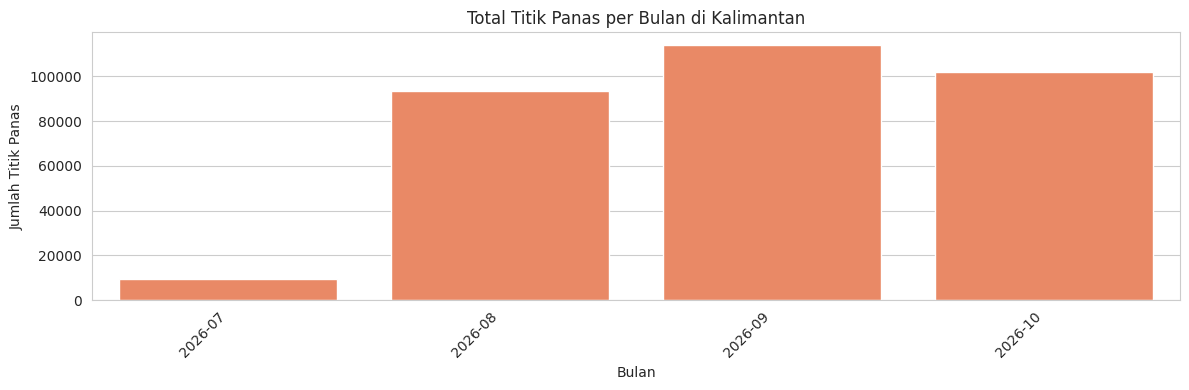


Puncak titik panas terjadi pada bulan: 2026-09


/tmp/ipykernel_620/1859768504.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_grids, y="label", x="hotspot_count", palette="Reds_r")


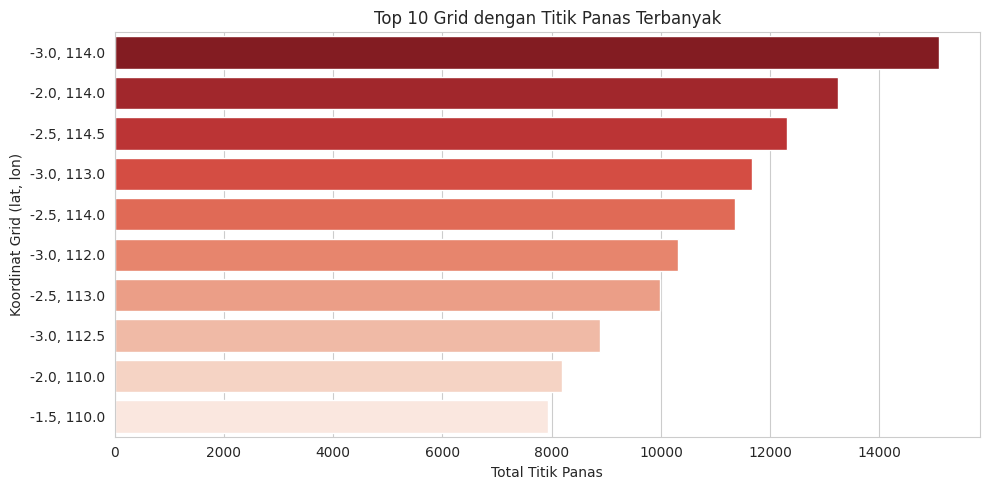

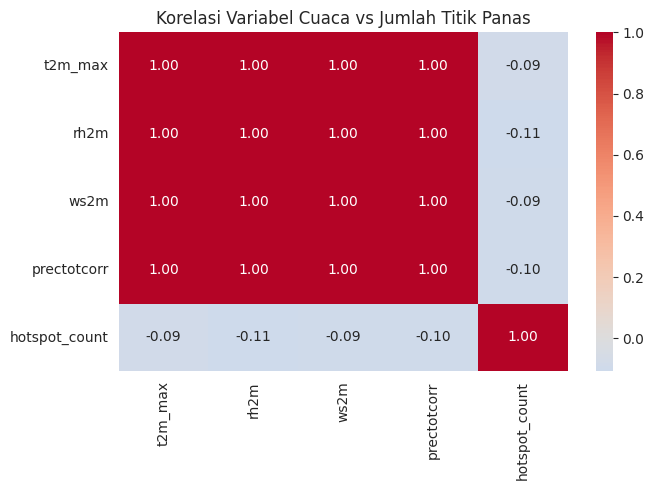


Interpretasi singkat:
- Korelasi positif dengan t2m_max (suhu) → makin panas, makin banyak titik panas.
- Korelasi negatif dengan rh2m (kelembaban) dan prectotcorr (hujan) → makin kering, makin rawan.
- ws2m (angin) bisa positif karena angin mempercepat penyebaran api.

Distribusi hotspot_count:
count    14145.000000
mean        22.516296
std         56.679195
min          1.000000
25%          2.000000
50%          5.000000
75%         17.000000
max       1411.000000
Name: hotspot_count, dtype: float64

Persentase grid-hari dengan hotspot_count = 0: 0.0%
Persentase grid-hari dengan hotspot_count > 0: 100.0%


In [3]:
# ============================================================
# EKSPLORASI DATA (EDA)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi tampilan
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# ============================================================
# 1 MUAT DATA HASIL SEL 1
# ============================================================
df = pd.read_csv("karhutla_kalimantan_merged.csv", parse_dates=["acq_date", "date"])

print("=" * 55)
print("RINGKASAN DATASET")
print("=" * 55)
print(f"Jumlah baris          : {len(df):,}")
print(f"Jumlah grid unik      : {df.groupby(['lat_grid','lon_grid']).ngroups}")
print(f"Rentang tanggal       : {df['acq_date'].min().date()} s/d {df['acq_date'].max().date()}")
print(f"Total titik panas     : {int(df['hotspot_count'].sum()):,}")
print(f"\nMissing values per kolom:")
print(df.isnull().sum())

# ============================================================
# 2 DISTRIBUSI TITIK PANAS PER BULAN
# ============================================================
df["month"] = df["acq_date"].dt.to_period("M").astype(str)

monthly = df.groupby("month")["hotspot_count"].sum().reset_index()

plt.figure(figsize=(12, 4))
sns.barplot(data=monthly, x="month", y="hotspot_count", color="coral")
plt.xticks(rotation=45, ha="right")
plt.title("Total Titik Panas per Bulan di Kalimantan")
plt.ylabel("Jumlah Titik Panas")
plt.xlabel("Bulan")
plt.tight_layout()
plt.show()

print("\nPuncak titik panas terjadi pada bulan:",
      monthly.loc[monthly["hotspot_count"].idxmax(), "month"])

# ============================================================
# 3 TOP 10 GRID DENGAN TITIK PANAS TERBANYAK
# ============================================================
top_grids = (
    df.groupby(["lat_grid", "lon_grid"])["hotspot_count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
top_grids["label"] = top_grids["lat_grid"].astype(str) + ", " + top_grids["lon_grid"].astype(str)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_grids, y="label", x="hotspot_count", palette="Reds_r")
plt.title("Top 10 Grid dengan Titik Panas Terbanyak")
plt.xlabel("Total Titik Panas")
plt.ylabel("Koordinat Grid (lat, lon)")
plt.tight_layout()
plt.show()

# ============================================================
# 4 KORELASI CUACA VS JUMLAH TITIK PANAS
# ============================================================
weather_cols = ["t2m_max", "rh2m", "ws2m", "prectotcorr", "hotspot_count"]
corr = df[weather_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Korelasi Variabel Cuaca vs Jumlah Titik Panas")
plt.tight_layout()
plt.show()

print("\nInterpretasi singkat:")
print("- Korelasi positif dengan t2m_max (suhu) → makin panas, makin banyak titik panas.")
print("- Korelasi negatif dengan rh2m (kelembaban) dan prectotcorr (hujan) → makin kering, makin rawan.")
print("- ws2m (angin) bisa positif karena angin mempercepat penyebaran api.")

# ============================================================
# 5 CEK DISTRIBUSI TARGET (KETIDAKSEIMBANGAN)
# ============================================================
# Target biner: apakah besok ada titik panas? (kita definisikan di Sel 3)
# Di sini kita cek dulu distribusi hotspot_count
print("\nDistribusi hotspot_count:")
print(df["hotspot_count"].describe())
print(f"\nPersentase grid-hari dengan hotspot_count = 0: "
      f"{(df['hotspot_count'] == 0).mean() * 100:.1f}%")
print(f"Persentase grid-hari dengan hotspot_count > 0: "
      f"{(df['hotspot_count'] > 0).mean() * 100:.1f}%")

In [4]:
# ============================================================
# REKAYASA FITUR
# Fitur lag (histori titik panas & hujan), target biner besok
# ============================================================

import pandas as pd
import numpy as np

df = pd.read_csv("karhutla_kalimantan_merged.csv", parse_dates=["acq_date", "date"])

# ============================================================
# 1 PASTIKAN SETIAP GRID PUNYA DERET HARIAN LENGKAP
# ============================================================
# Grid-hari yang tidak punya titik panas tidak muncul di data FIRMS,
# jadi kita perlu reindex agar ada baris untuk setiap grid × tanggal.
all_grids = df[["lat_grid", "lon_grid"]].drop_duplicates()
all_dates = pd.date_range(df["acq_date"].min(), df["acq_date"].max(), freq="D")

# Buat kerangka lengkap grid × tanggal
full_index = pd.MultiIndex.from_product(
    [all_grids.itertuples(index=False, name=None), all_dates],
    names=["grid", "acq_date"]
)
df_full = pd.DataFrame(index=full_index).reset_index()
df_full[["lat_grid", "lon_grid"]] = pd.DataFrame(df_full["grid"].tolist(), index=df_full.index)
df_full = df_full.drop(columns="grid")

# Gabungkan dengan data asli
df_full = df_full.merge(
    df[["lat_grid", "lon_grid", "acq_date", "hotspot_count",
        "t2m_max", "rh2m", "ws2m", "prectotcorr"]],
    on=["lat_grid", "lon_grid", "acq_date"],
    how="left"
)

# Isi hotspot_count yang NaN dengan 0 (tidak ada titik panas = 0)
df_full["hotspot_count"] = df_full["hotspot_count"].fillna(0).astype(int)

# Untuk cuaca: forward-fill per grid (cuaca tidak berubah drastis antar hari)
df_full = df_full.sort_values(["lat_grid", "lon_grid", "acq_date"])
df_full[["t2m_max", "rh2m", "ws2m", "prectotcorr"]] = (
    df_full.groupby(["lat_grid", "lon_grid"])[["t2m_max", "rh2m", "ws2m", "prectotcorr"]]
    .transform(lambda s: s.ffill().bfill())
)

print(f"Setelah reindex lengkap: {len(df_full):,} baris")
print(f"Missing values tersisa:\n{df_full.isnull().sum()}")

# ============================================================
# 2 FITUR LAG (HISTORI)
# ============================================================
grp = df_full.groupby(["lat_grid", "lon_grid"])

# Lag titik panas: 1, 3, 7 hari terakhir (rolling sum)
df_full["hotspot_lag1"]  = grp["hotspot_count"].shift(1)
df_full["hotspot_lag3"]  = grp["hotspot_count"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).sum())
df_full["hotspot_lag7"]  = grp["hotspot_count"].transform(lambda s: s.shift(1).rolling(7, min_periods=1).sum())

# Akumulasi hujan 7 & 14 hari (indikator kekeringan)
df_full["rain_7d"]  = grp["prectotcorr"].transform(lambda s: s.rolling(7,  min_periods=1).sum())
df_full["rain_14d"] = grp["prectotcorr"].transform(lambda s: s.rolling(14, min_periods=1).sum())

# Fitur kalender
df_full["month"]      = df_full["acq_date"].dt.month
df_full["dayofyear"]  = df_full["acq_date"].dt.dayofyear

# ============================================================
# 3 TARGET BINER: APAKAH BESOK ADA TITIK PANAS?
# ============================================================
df_full["target"] = (
    grp["hotspot_count"].shift(-1).fillna(0) > 0
).astype(int)

# ============================================================
# 4 BERSIHKAN BARIS YANG TIDAK VALID
# ============================================================
# Buang baris awal yang lag-nya belum terbentuk (7 hari pertama per grid)
df_model = df_full.dropna(subset=["hotspot_lag7", "rain_14d"]).copy()

# Buang baris terakhir (target = NaN karena shift -1)
df_model = df_model[df_model["acq_date"] < df_model["acq_date"].max()]

print(f"\nDataset siap model: {len(df_model):,} baris")
print(f"Distribusi target:")
print(df_model["target"].value_counts(normalize=True).round(3))
print(f"\nKolom akhir: {list(df_model.columns)}")

# Simpan
df_model.to_csv("karhutla_features.csv", index=False)
print("\n✅ Fitur tersimpan: karhutla_features.csv")
print(df_model.head())

Setelah reindex lengkap: 33,345 baris
Missing values tersisa:
acq_date         0
lat_grid         0
lon_grid         0
hotspot_count    0
t2m_max          0
rh2m             0
ws2m             0
prectotcorr      0
dtype: int64

Dataset siap model: 32,775 baris
Distribusi target:
target
0    0.57
1    0.43
Name: proportion, dtype: float64

Kolom akhir: ['acq_date', 'lat_grid', 'lon_grid', 'hotspot_count', 't2m_max', 'rh2m', 'ws2m', 'prectotcorr', 'hotspot_lag1', 'hotspot_lag3', 'hotspot_lag7', 'rain_7d', 'rain_14d', 'month', 'dayofyear', 'target']

✅ Fitur tersimpan: karhutla_features.csv
    acq_date  lat_grid  lon_grid  hotspot_count  t2m_max   rh2m  ws2m  \
1 2026-07-02      -4.0     108.0              0    28.42  80.69  5.65   
2 2026-07-03      -4.0     108.0              0    28.42  80.69  5.65   
3 2026-07-04      -4.0     108.0              0    28.42  80.69  5.65   
4 2026-07-05      -4.0     108.0              0    28.42  80.69  5.65   
5 2026-07-06      -4.0     108.0        

DISTRIBUSI TARGET
target
0    0.5699
1    0.4301
Name: proportion, dtype: float64

Train: 12,825 baris (2026-07-02 s/d 2026-08-15)
Test : 19,950 baris (2026-08-16 s/d 2026-10-24)
Rasio positif train: 0.371
Rasio positif test : 0.468

BASELINE: LOGISTIC REGRESSION
PR-AUC : 0.8298
ROC-AUC: 0.8202

MODEL UTAMA: XGBOOST
PR-AUC : 0.8502
ROC-AUC: 0.8763

                         Model   PR-AUC  ROC-AUC
Logistic Regression (baseline) 0.829792 0.820181
                       XGBoost 0.850197 0.876329


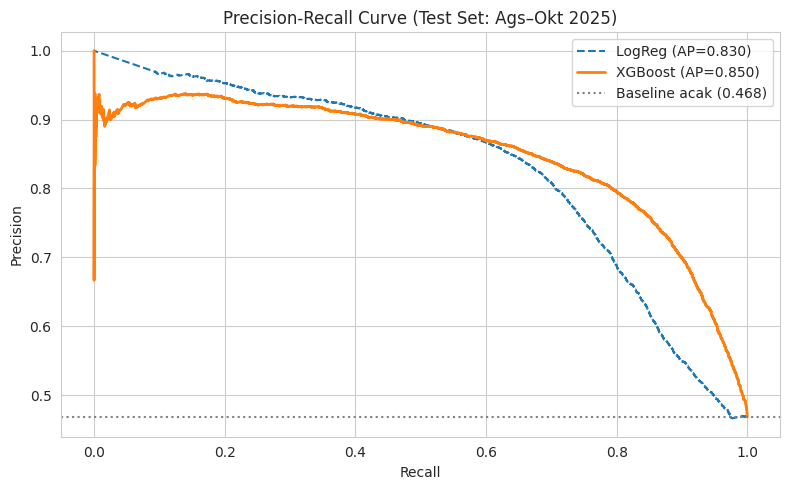

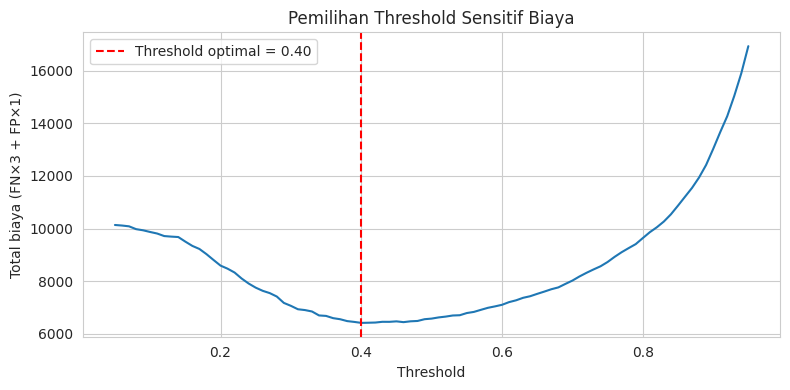


Threshold optimal (cost-sensitive): 0.40

Classification report pada threshold ini:
              precision    recall  f1-score   support

           0      0.886     0.644     0.746     10608
           1      0.692     0.906     0.784      9342

    accuracy                          0.767     19950
   macro avg      0.789     0.775     0.765     19950
weighted avg      0.795     0.767     0.764     19950



In [10]:
# ============================================================
# MODELING
# Baseline Logistic Regression + XGBoost + Time-Based Split
# ============================================================

!pip install -q xgboost scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    roc_auc_score, classification_report, confusion_matrix
)
from xgboost import XGBClassifier

sns.set_style("whitegrid")

# ============================================================
# 1 MUAT DATA & DEFINISIKAN FITUR
# ============================================================
df = pd.read_csv("karhutla_features.csv", parse_dates=["acq_date"])

FEATURES = [
    "t2m_max", "rh2m", "ws2m", "prectotcorr",
    "hotspot_lag1", "hotspot_lag3", "hotspot_lag7",
    "rain_7d", "rain_14d",
    "month", "dayofyear",
]
TARGET = "target"

print("=" * 55)
print("DISTRIBUSI TARGET")
print("=" * 55)
print(df[TARGET].value_counts(normalize=True).round(4))

# ============================================================
# 2 TIME-BASED SPLIT
# ============================================================
# Latih: 2026-03 s/d 2026-07 ; Uji: 2026-08 s/d 2026-10
# Alasan: random split akan membuat model "melihat" masa depan (data leakage)
SPLIT_DATE = pd.Timestamp("2026-08-16")

train = df[df["acq_date"] < SPLIT_DATE].copy()
test  = df[df["acq_date"] >= SPLIT_DATE].copy()

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print(f"\nTrain: {len(train):,} baris ({train['acq_date'].min().date()} s/d {train['acq_date'].max().date()})")
print(f"Test : {len(test):,} baris ({test['acq_date'].min().date()} s/d {test['acq_date'].max().date()})")
print(f"Rasio positif train: {y_train.mean():.3f}")
print(f"Rasio positif test : {y_test.mean():.3f}")

# ============================================================
# 3 BASELINE: LOGISTIC REGRESSION
# ============================================================
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
lr_pipe.fit(X_train, y_train)
lr_proba = lr_pipe.predict_proba(X_test)[:, 1]
lr_pr_auc = average_precision_score(y_test, lr_proba)

print("\n" + "=" * 55)
print("BASELINE: LOGISTIC REGRESSION")
print("=" * 55)
print(f"PR-AUC : {lr_pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, lr_proba):.4f}")

# ============================================================
# 4 MODEL UTAMA: XGBOOST
# ============================================================
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]
xgb_pr_auc = average_precision_score(y_test, xgb_proba)

print("\n" + "=" * 55)
print("MODEL UTAMA: XGBOOST")
print("=" * 55)
print(f"PR-AUC : {xgb_pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, xgb_proba):.4f}")

# ============================================================
# 5 PERBANDINGAN MODEL
# ============================================================
comparison = pd.DataFrame({
    "Model": ["Logistic Regression (baseline)", "XGBoost"],
    "PR-AUC": [lr_pr_auc, xgb_pr_auc],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_proba),
        roc_auc_score(y_test, xgb_proba),
    ],
})
print("\n" + comparison.to_string(index=False))

# ============================================================
# 6 KURVA PRECISION-RECALL
# ============================================================
prec_lr, rec_lr, _ = precision_recall_curve(y_test, lr_proba)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, xgb_proba)

plt.figure(figsize=(8, 5))
plt.plot(rec_lr, prec_lr, label=f"LogReg (AP={lr_pr_auc:.3f})", linestyle="--")
plt.plot(rec_xgb, prec_xgb, label=f"XGBoost (AP={xgb_pr_auc:.3f})", linewidth=2)
plt.axhline(y=y_test.mean(), color="gray", linestyle=":", label=f"Baseline acak ({y_test.mean():.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Test Set: Ags–Okt 2025)")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 7 PEMILIHAN THRESHOLD SENSITIF BIAYA
# ============================================================
# Asumsi bisnis: melewatkan hotspot (FN) 3x lebih mahal
# daripada false alarm (FP) yang hanya memicu patroli ekstra.
COST_FN = 3.0
COST_FP = 1.0

thresholds = np.arange(0.05, 0.96, 0.01)
costs = []
for t in thresholds:
    y_pred = (xgb_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    total_cost = fn * COST_FN + fp * COST_FP
    costs.append(total_cost)

best_idx = int(np.argmin(costs))
best_threshold = thresholds[best_idx]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="red", linestyle="--",
            label=f"Threshold optimal = {best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Total biaya (FN×3 + FP×1)")
plt.title("Pemilihan Threshold Sensitif Biaya")
plt.legend()
plt.tight_layout()
plt.show()

# Evaluasi pada threshold optimal
y_pred_best = (xgb_proba >= best_threshold).astype(int)
print(f"\nThreshold optimal (cost-sensitive): {best_threshold:.2f}")
print("\nClassification report pada threshold ini:")
print(classification_report(y_test, y_pred_best, digits=3))

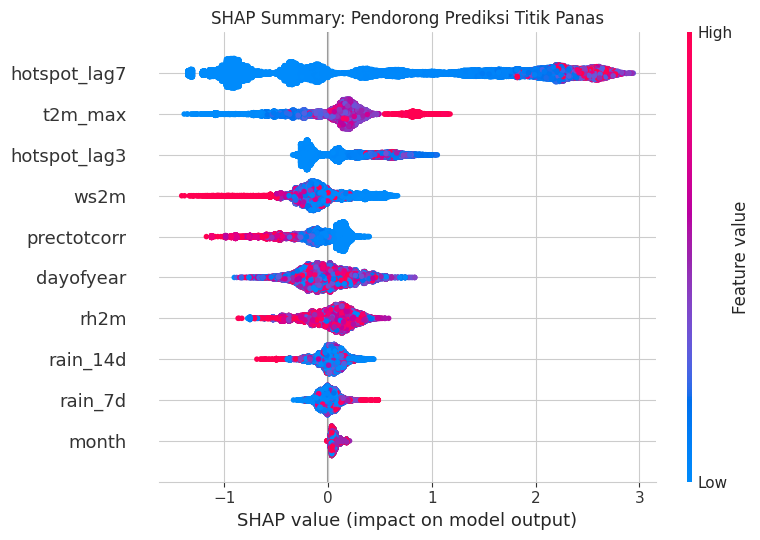


RANKING FITUR (mean |SHAP|)
hotspot_lag7    1.2138
t2m_max         0.2950
hotspot_lag3    0.2947
ws2m            0.2140
prectotcorr     0.2053
dayofyear       0.1951
rh2m            0.1672
rain_14d        0.0960
rain_7d         0.0678
month           0.0572
hotspot_lag1    0.0550

Jumlah grid-hari berisiko tinggi (proba >= 0.40): 12,234

Perbandingan profil risiko tinggi vs rendah:
       Fitur  Rata-rata (Risiko Tinggi)  Rata-rata (Risiko Rendah)  Selisih
hotspot_lag7                     152.85                       1.49   151.36
hotspot_lag3                      67.22                       0.49    66.73
hotspot_lag1                      22.97                       0.16    22.81
       month                       9.03                       9.25    -0.22
   dayofyear                     259.99                     266.48    -6.49
     t2m_max                      -1.43                      28.99   -30.42
        ws2m                     -30.49                       1.25   -31.74
 prect

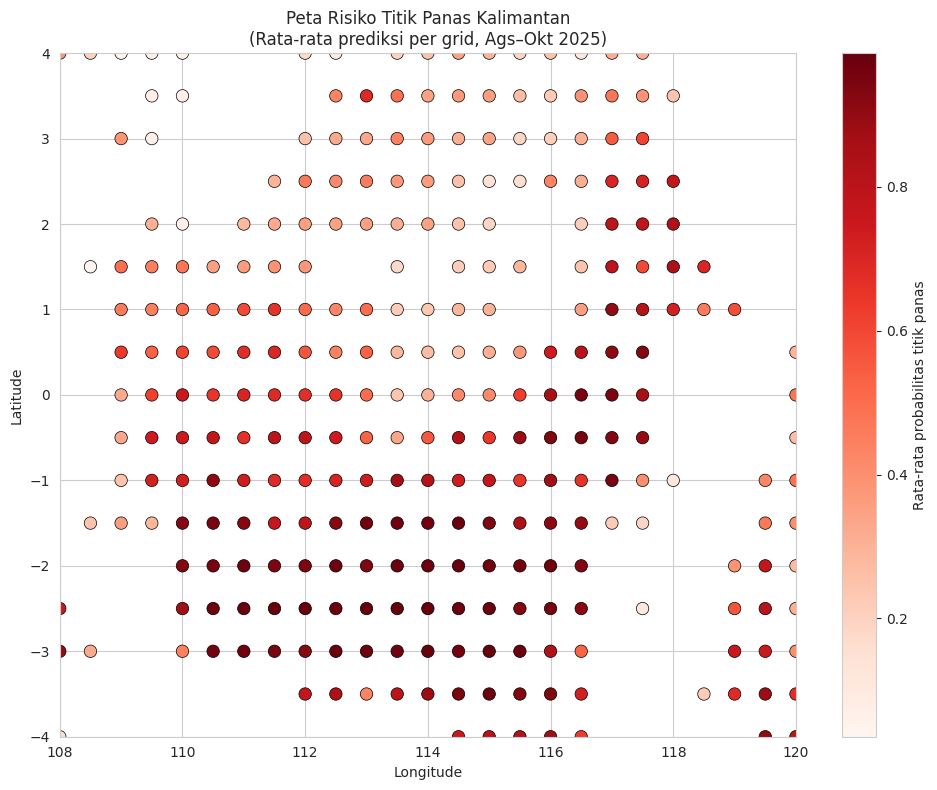

✅ Peta tersimpan: risk_map.png

TOP 5 GRID RISIKO TERTINGGI
 lat_grid  lon_grid  proba
     -2.5     113.0  0.986
     -2.5     114.0  0.985
     -2.5     113.5  0.985
     -2.5     111.5  0.981
     -3.0     114.0  0.981


In [11]:
# ============================================================
# INTERPRETASI + ATURAN + PETA RISIKO
# ============================================================

!pip install -q shap geopandas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

sns.set_style("whitegrid")

# ============================================================
# 1 SHAP: FITUR MANA YANG PALING BERPENGARUH?
# ============================================================
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure()
shap.summary_plot(shap_values, X_test, show=False, max_display=10)
plt.title("SHAP Summary: Pendorong Prediksi Titik Panas")
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=120, bbox_inches="tight")
plt.show()

# Ranking fitur
mean_abs_shap = pd.Series(
    np.abs(shap_values).mean(axis=0), index=FEATURES
).sort_values(ascending=False)

print("\n" + "=" * 55)
print("RANKING FITUR (mean |SHAP|)")
print("=" * 55)
print(mean_abs_shap.round(4).to_string())

# ============================================================
# 2 EKSTRAKSI ATURAN YANG DAPAT DIPAHAMI MANUSIA
# ============================================================
# Ambil sampel prediksi berisiko tinggi, lalu cari pola threshold
high_risk = X_test.copy()
high_risk["proba"] = xgb_proba
high_risk = high_risk[high_risk["proba"] >= best_threshold]

print(f"\nJumlah grid-hari berisiko tinggi (proba >= {best_threshold:.2f}): {len(high_risk):,}")

# Statistik deskriptif pada kelompok berisiko tinggi vs rendah
low_risk = X_test.copy()
low_risk["proba"] = xgb_proba
low_risk = low_risk[low_risk["proba"] < best_threshold]

compare = pd.DataFrame({
    "Fitur": FEATURES,
    "Rata-rata (Risiko Tinggi)": [high_risk[f].mean() for f in FEATURES],
    "Rata-rata (Risiko Rendah)": [low_risk[f].mean() for f in FEATURES],
})
compare["Selisih"] = compare["Rata-rata (Risiko Tinggi)"] - compare["Rata-rata (Risiko Rendah)"]
compare = compare.sort_values("Selisih", ascending=False)
print("\nPerbandingan profil risiko tinggi vs rendah:")
print(compare.round(2).to_string(index=False))

# Rumuskan aturan manual berbasis median kelompok berisiko tinggi
rules = {
    "Suhu maksimum": f"> {high_risk['t2m_max'].median():.1f}°C",
    "Kelembaban relatif": f"< {high_risk['rh2m'].median():.0f}%",
    "Curah hujan 7 hari": f"< {high_risk['rain_7d'].median():.1f} mm",
    "Titik panas 3 hari terakhir": f">= {high_risk['hotspot_lag3'].median():.0f}",
}
print("\n" + "=" * 55)
print("ATURAN RISIKO TINGGI (dari profil data)")
print("=" * 55)
for k, v in rules.items():
    print(f"  • {k} {v}")

# Simpan tabel aturan
pd.DataFrame(list(rules.items()), columns=["Fitur", "Ambang"]).to_csv(
    "rules_table.csv", index=False
)
print("\n✅ Aturan tersimpan: rules_table.csv")

# ============================================================
# 3 PETA RISIKO KALIMANTAN
# ============================================================
import geopandas as gpd
from shapely.geometry import Point

# Gabungkan prediksi ke koordinat grid
risk_map_df = test[["lat_grid", "lon_grid"]].copy()
risk_map_df["proba"] = xgb_proba
risk_agg = risk_map_df.groupby(["lat_grid", "lon_grid"])["proba"].mean().reset_index()

# Buat GeoDataFrame
geometry = [Point(lon, lat) for lat, lon in zip(risk_agg["lat_grid"], risk_agg["lon_grid"])]
gdf = gpd.GeoDataFrame(risk_agg, geometry=geometry, crs="EPSG:4326")

# Batas administratif (opsional): gunakan Natural Earth via geopandas
try:
    world = gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
    indo = world[world["name"] == "Indonesia"]
except Exception:
    indo = None

# Plot peta
fig, ax = plt.subplots(figsize=(10, 8))
if indo is not None:
    indo.plot(ax=ax, color="lightgray", edgecolor="black", linewidth=0.5)

scatter = ax.scatter(
    gdf.geometry.x, gdf.geometry.y,
    c=gdf["proba"], cmap="Reds", s=80,
    edgecolor="black", linewidth=0.5
)
cbar = plt.colorbar(scatter, ax=ax, label="Rata-rata probabilitas titik panas")
ax.set_title("Peta Risiko Titik Panas Kalimantan\n(Rata-rata prediksi per grid, Ags–Okt 2025)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(108, 120)
ax.set_ylim(-4, 4)
plt.tight_layout()
plt.savefig("risk_map.png", dpi=120, bbox_inches="tight")
plt.show()

print("✅ Peta tersimpan: risk_map.png")

# ============================================================
# 4 TOP 5 GRID PALING BERISIKO
# ============================================================
top_risk = risk_agg.sort_values("proba", ascending=False).head(5)
print("\n" + "=" * 55)
print("TOP 5 GRID RISIKO TERTINGGI")
print("=" * 55)
print(top_risk.round(3).to_string(index=False))

Mengunduh shapefile batas administrasi...
✅ Shapefile berhasil dimuat dan dipotong.


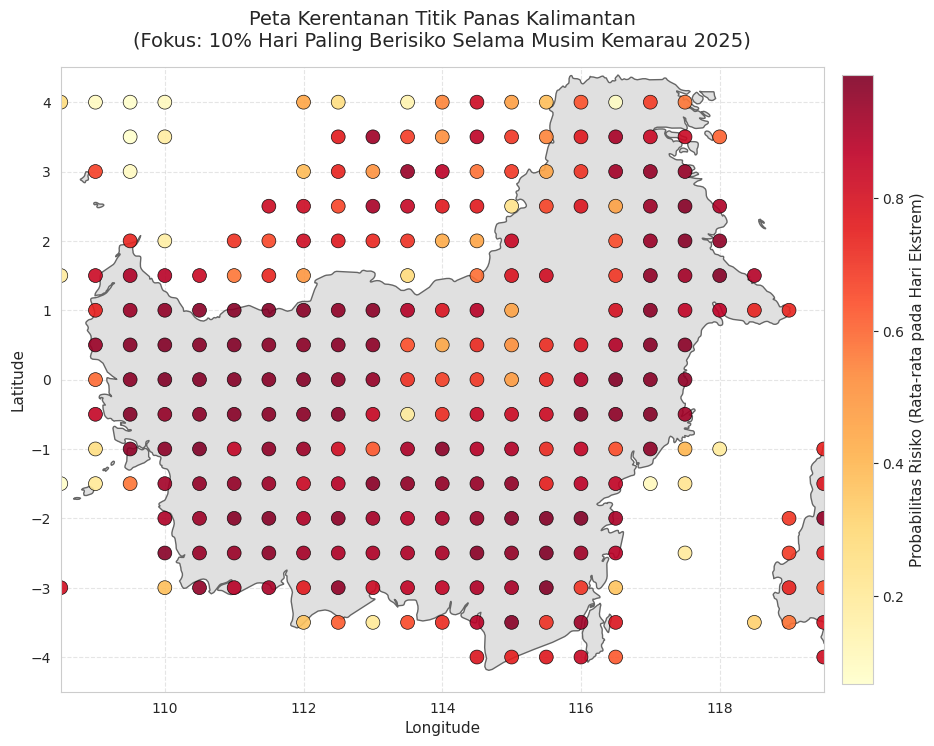


✅ Peta yang diperbaiki tersimpan sebagai: risk_map_improved.png


In [12]:
# ============================================================
# PERBAIKAN PETA RISIKO (KONTUR & TOP 10% HARI EKSTREM)
# ============================================================

!pip install -q geopandas shapely matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point
import requests
import io

# ============================================================
# 1 IDENTIFIKASI "HARI EKSTREM" (TOP 10% RISIKO TERTINGGI)
# ============================================================
# Pastikan df_test_pred dari sel sebelumnya tetap ada
if 'df_test_pred' not in locals():
    df_test_pred = test.copy()
    df_test_pred["proba"] = xgb_proba

# Hitung rata-rata probabilitas per hari
daily_risk = df_test_pred.groupby("acq_date")["proba"].mean().reset_index()

# Ambil threshold untuk top 10% hari paling berisiko
top_10_percent_threshold = daily_risk["proba"].quantile(0.90)
extreme_days = daily_risk[daily_risk["proba"] >= top_10_percent_threshold]["acq_date"]

# Filter prediksi hanya pada hari-hari ekstrem
df_extreme = df_test_pred[df_test_pred["acq_date"].isin(extreme_days)]

# Agregasi rata-rata per grid pada hari ekstrem
risk_agg_extreme = df_extreme.groupby(["lat_grid", "lon_grid"])["proba"].mean().reset_index()

# ============================================================
# 2 UNDUH BATAS ADMINISTRASI (KONTUR PULAU)
# ============================================================
print("Mengunduh shapefile batas administrasi...")
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_admin_0_countries.geojson"

try:
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    world = gpd.read_file(io.StringIO(response.text))

    # Ambil poligon Indonesia
    indo = world[world["ADMIN"] == "Indonesia"]

    # Potong (crop) hanya area Kalimantan menggunakan bounding box
    from shapely.geometry import box
    bbox_poly = box(108, -4.5, 120, 4.5)
    kalimantan_geom = indo.intersection(bbox_poly)

    # Buat GeoDataFrame baru untuk Kalimantan
    kalimantan_gdf = gpd.GeoDataFrame(geometry=kalimantan_geom, crs="EPSG:4326")
    print("✅ Shapefile berhasil dimuat dan dipotong.")
except Exception as e:
    print(f"⚠️ Gagal mengunduh shapefile: {e}")
    kalimantan_gdf = None

# ============================================================
# 3 BUAT PETA YANG LEBIH BAIK (PLOT OVERLAY)
# ============================================================
fig, ax = plt.subplots(figsize=(10, 9))

# Plot kontur daratan Kalimantan (warna abu-abu terang)
if kalimantan_gdf is not None:
    kalimantan_gdf.plot(ax=ax, color="#e0e0e0", edgecolor="#666666", linewidth=1, zorder=1)

# Plot grid risiko di atasnya
scatter = ax.scatter(
    risk_agg_extreme["lon_grid"],
    risk_agg_extreme["lat_grid"],
    c=risk_agg_extreme["proba"],
    cmap="YlOrRd",   # Yellow-Orange-Red (kontras)
    s=100,           # Ukuran titik
    edgecolor="black",
    linewidth=0.5,
    alpha=0.9,
    zorder=2         # Pastikan titik di atas peta
)

# Kustomisasi Peta
cbar = plt.colorbar(scatter, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label("Probabilitas Risiko (Rata-rata pada Hari Ekstrem)", fontsize=11)

ax.set_title("Peta Kerentanan Titik Panas Kalimantan\n(Fokus: 10% Hari Paling Berisiko Selama Musim Kemarau 2025)", fontsize=14, pad=15)
ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude", fontsize=11)
ax.set_xlim(108.5, 119.5)
ax.set_ylim(-4.5, 4.5)
ax.grid(True, linestyle="--", alpha=0.5, zorder=0)

plt.tight_layout()
plt.savefig("risk_map_improved.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n✅ Peta yang diperbaiki tersimpan sebagai: risk_map_improved.png")